<div style="background:linear-gradient(135deg,#0c4a6e 0%,#0369a1 55%,#7dd3fc 100%);border-radius:18px;padding:32px 30px;color:#fff;font-family:Inter,Segoe UI,sans-serif">
  <div style="font-size:12px;letter-spacing:3px;color:#bae6fd;font-weight:700;text-transform:uppercase">Chapter 201 &middot; Capstone 38 &middot; Backtesting</div>
  <div style="font-size:32px;font-weight:900;line-height:1.1;margin:10px 0 6px">Choosing a Forecast Honestly</div>
  <div style="font-size:15px;color:#bae6fd;max-width:820px;line-height:1.6">A bake-off tried thirty-two models, scored them on last year, and reported a winner that forecasts within 3.4 percent. Next year's production plan was built on that number. This notebook re-runs the evaluation and finds where the 3.4 percent came from.</div>
</div>

In [1]:
import numpy as np, pandas as pd, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
plt.rcParams.update({"figure.dpi":110,"font.size":11,"axes.spines.top":False,"axes.spines.right":False,
    "axes.grid":True,"grid.alpha":0.22,"axes.titleweight":"bold","axes.titlesize":12.5,"axes.titlelocation":"left"})
SK, DK, LT, MUT, GD, RD = "#0369a1", "#0c4a6e", "#7dd3fc", "#94a3b8", "#047857", "#dc2626"

BASE_URL = "https://raw.githubusercontent.com/johnfisher-ai/Statistics-Data-Science-AI-Visual-Book/main/data/"
fn = "capstone-forecast-backtesting.xlsx"
def load(sheet):
    try:    return pd.read_excel("../../data/" + fn, sheet_name=sheet)
    except FileNotFoundError: return pd.read_excel(BASE_URL + fn, sheet_name=sheet)
raw   = load("Data")
notes = load("Notes")
H = 12                                   # the plan needs twelve months
print("rows in the shipments extract:", len(raw))
raw.head()

rows in the shipments extract: 156


,month,cases_shipped
0,Jan-2013,3601
1,Feb-2013,3511
2,Mar-2013,3992
3,Apr-2013,4278
4,May-2013,4331


## Step 1 &middot; The brief

In [2]:
for line in notes.Notes.fillna(""):
    print(line)

MONTHLY SHIPMENTS. Cases shipped to wholesale grocery accounts, January 2013 onward.

THE JOB. Last year the planning team ran a bake-off. They fitted thirty-two forecasting
configurations, scored each one on the most recent twelve months, picked the winner, and
reported that it forecasts within 3.4 percent. Next year's production plan, the hiring
plan and the raw-material contracts were all built on that number.

THE QUESTION. Is 3.4 percent what this business should expect next year?

WHAT IS IN THE EXPORT, as it arrived:
 - the extract was pulled on 12 January 2026, so the last row covers eleven days of
   January and is not a complete month
 - July and August 2017 are missing. The ERP migration ran that summer
 - March 2021 is recorded ten times too large, a decimal slip
 - June 2019 was exported twice
 - the month column is written two ways, Jan-2013 before 2017 and 2017-01-01 after


Two words in there decide the whole notebook.

**Picked.** The team did not fit one model and measure it. They fitted thirty-two and kept the one that scored best. Measuring a model you chose for its score on the same data that produced the score is a different act from measuring a model someone handed you, and the difference has a size that can be worked out.

**Last year.** One year is one draw. The question is not only whether 3.4 percent is a good number but how much that number would have moved had the bake-off been run a quarter earlier, or a quarter later.

Everything below is one test: **hold back three years that nothing is allowed to touch, re-run the bake-off on the rest, and only at the end open the sealed period and see what each procedure actually bought.**

## Step 2 &middot; Cleaning

In [3]:
d = raw.copy()
d["month"] = pd.to_datetime(d.month, format="mixed")     # Jan-2013 and 2017-01-01 both appear

n_dup = d.duplicated("month").sum()
d = d.drop_duplicates("month").sort_values("month").reset_index(drop=True)
print(f"duplicate months        {n_dup} dropped (June 2019 was exported twice)")

tail = d.iloc[-1]
d = d.iloc[:-1].copy()
print(f"partial final month     {tail.month:%b %Y} dropped, {tail.cases_shipped:,} cases over 11 days")

full = pd.date_range(d.month.min(), d.month.max(), freq="MS")
gap  = sorted(set(full) - set(d.month))
print(f"months absent           {len(gap)}: {', '.join(f'{g:%b %Y}' for g in gap)}")
s = d.set_index("month").cases_shipped.reindex(full).astype(float)

duplicate months        1 dropped (June 2019 was exported twice)
partial final month     Jan 2026 dropped, 1,975 cases over 11 days
months absent           2: Jul 2017, Aug 2017


**The partial month is the dangerous one.** Eleven days of January booked as a month reads as a 64 percent collapse against the same month a year earlier. It is the most recent point in the file, so it lands in the training window of every forecast made from the end of the series and drags the level down exactly where the level matters most. A row that is not what its column says it is does more damage the later it sits.

**The gap matters for a reason specific to time series.** With July and August 2017 absent the file still has rows, just fewer of them, and anything that reaches back twelve *positions* instead of twelve *months* silently starts comparing the wrong months. Reindexing onto a complete monthly calendar puts the missing months back as gaps that have to be dealt with openly.

In [4]:
yoy  = s/s.shift(12)
slip = yoy[yoy > 5].index
for t in slip:
    print(f"decimal slip            {t:%b %Y}: {s[t]:,.0f} cases, {yoy[t]:.1f}x the same month a year earlier")
s[slip] = s[slip]/10
print(f"                        corrected to {s[slip[0]]:,.0f}")

ratio = s/s.rolling(12, center=True).mean()          # ratio to a centered moving average
sf    = ratio.groupby(ratio.index.month).mean(); sf = sf/sf.mean()
des   = s/s.index.month.map(sf)                      # deseasonalize, interpolate, reseasonalize
s     = (des.interpolate("linear")*s.index.month.map(sf)).round()
print(f"gap filled              {', '.join(f'{g:%b %Y} = {s[g]:,.0f}' for g in gap)}")

y = s.to_numpy(float); T = len(y)
print(f"\nclean series            {T} months, {full[0]:%b %Y} to {full[-1]:%b %Y}, no gaps")

decimal slip            Mar 2021: 57,270 cases, 9.9x the same month a year earlier
                        corrected to 5,727
gap filled              Jul 2017 = 4,222, Aug 2017 = 4,231

clean series            156 months, Jan 2013 to Dec 2025, no gaps


**Ten times too large is easier to catch than to fix.** Against the same month a year earlier March 2021 is 9.9 times its own history, which is not a demand story, it is a keystroke. Dividing by ten is defensible here precisely because the ratio is so close to ten. Had it been 3.2 times, the honest move would be to treat the month as missing rather than to guess at what it should have been.

**Filling the gap is a decision, not a formality.** Interpolating a straight line through July and August would have ignored that those are quiet months, so the level is interpolated with the seasonality divided out and put back afterward. Two of 156 months are now partly invented, and every backtest below trains across them. It is a small debt but it is real, and Step 12 says so out loud.

## Step 3 &middot; First look

In [5]:
ann = s.resample("YE").sum(); g = ann.pct_change().dropna()
print(f"cases per month     {y.min():,.0f} to {y.max():,.0f}, mean {y.mean():,.0f}")
print(f"annual growth       median {g.median():+.1%}, from {g.min():+.1%} to {g.max():+.1%}")
print(f"strongest month     December, {s.groupby(s.index.month).mean()[12]/y.mean()-1:+.0%} of the average month")
print(f"2018 to 2020        {g['2018':'2020'].mean():+.1%} a year")
print(f"2021 to 2024        {g['2021':'2024'].mean():+.1%} a year")

cases per month     3,326 to 8,596, mean 5,457
annual growth       median +3.4%, from -1.7% to +11.9%
strongest month     December, +29% of the average month
2018 to 2020        +10.3% a year
2021 to 2024        +0.7% a year


**What this shows.** The business shipped two-thirds more in 2025 than in 2013, but it did not get there steadily: three years above ten percent a year, then four averaging under one. A forecasting method that assumes a trend and one that assumes none will both look right somewhere in this history, which is the whole problem the chapter is about.

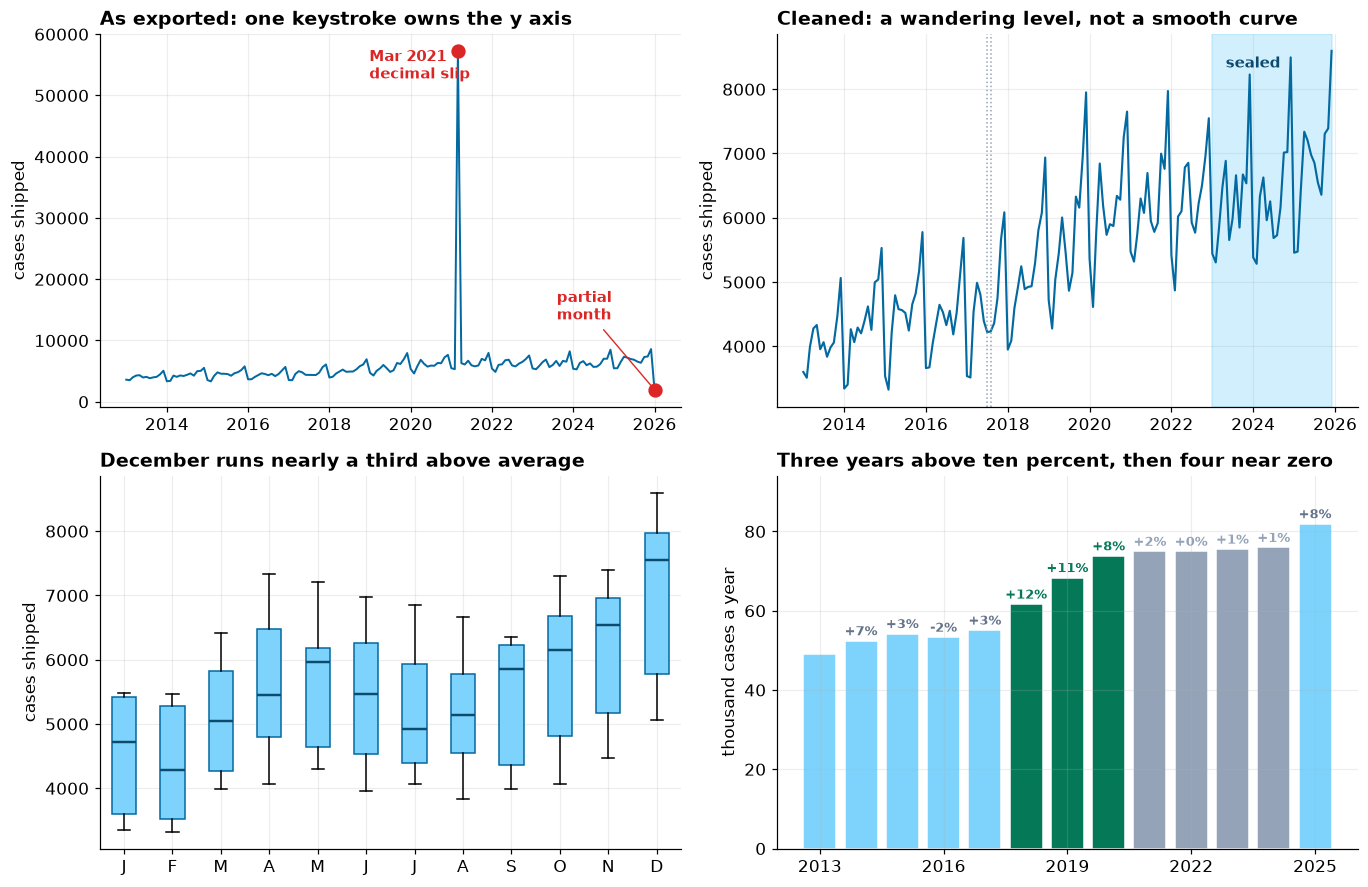

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(12.6, 8.2))

raw_s = raw.copy(); raw_s["month"] = pd.to_datetime(raw_s.month, format="mixed")
raw_s = raw_s.drop_duplicates("month").set_index("month").cases_shipped
ax[0,0].plot(raw_s.index, raw_s.values, color=SK, lw=1.3)
ax[0,0].scatter([slip[0]], [raw_s[slip[0]]], s=70, color=RD, zorder=5)
ax[0,0].annotate("Mar 2021\ndecimal slip", (slip[0], raw_s[slip[0]]), textcoords="offset points",
                 xytext=(-58, -18), fontsize=9.5, color=RD, fontweight="bold")
ax[0,0].scatter([raw_s.index[-1]], [raw_s.iloc[-1]], s=70, color=RD, zorder=5)
ax[0,0].annotate("partial\nmonth", (raw_s.index[-1], raw_s.iloc[-1]), textcoords="offset points",
                 xytext=(-64, 46), fontsize=9.5, color=RD, fontweight="bold",
                 arrowprops=dict(arrowstyle="-", color=RD, lw=0.9))
ax[0,0].set_title("As exported: one keystroke owns the y axis")
ax[0,0].set_ylabel("cases shipped")

ax[0,1].plot(full, y, color=SK, lw=1.4)
ax[0,1].axvspan(full[120], full[-1], color=LT, alpha=0.35)
ax[0,1].text(full[132], y.max()*0.97, "sealed", ha="center", fontsize=10, color=DK, fontweight="bold")
for gg in gap: ax[0,1].axvline(gg, color=MUT, lw=1.0, ls=":")
ax[0,1].set_title("Cleaned: a wandering level, not a smooth curve")
ax[0,1].set_ylabel("cases shipped")

P = pd.DataFrame({"m": full.month, "v": y})
ax[1,0].boxplot([P.v[P.m == k] for k in range(1, 13)], tick_labels=list("JFMAMJJASOND"),
                patch_artist=True, medianprops=dict(color=DK, lw=1.6),
                boxprops=dict(facecolor=LT, edgecolor=SK), flierprops=dict(markersize=3, markerfacecolor=MUT))
ax[1,0].set_title("December runs nearly a third above average")
ax[1,0].set_ylabel("cases shipped")

band = lambda yr: GD if 2018 <= yr <= 2020 else (MUT if 2021 <= yr <= 2024 else LT)
ax[1,1].bar(ann.index.year, ann.values/1000, color=[band(yr) for yr in ann.index.year], edgecolor="white")
for yr, v in zip(ann.index.year[1:], g):
    ax[1,1].text(yr, ann[str(yr)].iloc[0]/1000+1.4, f"{v:+.0%}", ha="center", fontsize=8.5,
                 color=band(yr) if band(yr) != LT else "#64748b", fontweight="bold")
ax[1,1].set_xticks(range(2013, 2026, 3)); ax[1,1].set_ylim(0, 94)
ax[1,1].set_title("Three years above ten percent, then four near zero")
ax[1,1].set_ylabel("thousand cases a year")
plt.tight_layout(); plt.show()

**Top left.** The series as the file delivers it. A single mistyped month is ten times the height of the business and flattens everything else into a band, and the partial January hangs off the end like a crash. Neither is a fact about shipments.

**Top right.** The same series cleaned, with the three sealed years shaded and the filled gap marked. The level wanders rather than following a smooth path, which is the property that makes a twelve-month-ahead forecast much less certain than a one-month-ahead one.

**Bottom left.** December runs 29 percent above the average month and February 20 percent below. Any method that ignores this loses to one that does not, so the interesting comparisons are all among methods that handle seasonality.

**Bottom right.** The growth rate is not a constant. 2018 through 2020 averaged over ten percent a year, 2021 through 2024 averaged under one. **A year picked out of this history to test on is not interchangeable with any other year.**

## Step 4 &middot; The evaluation design

In [7]:
DEV  = 120                                   # Jan 2013 - Dec 2022 is all anyone may look at
ORIG = list(range(60, DEV-H+1, 3))           # rolling origins, every 3 months
SEAL = [DEV, DEV+H, DEV+2*H]                 # three sealed years, opened once, at Step 9

print(f"development   {full[0]:%b %Y} to {full[DEV-1]:%b %Y}   ({DEV} months)")
print(f"sealed        {full[DEV]:%b %Y} to {full[-1]:%b %Y}   ({T-DEV} months, untouched until Step 9)")
print(f"origins       {len(ORIG)}, forecasting the 12 months from {full[ORIG[0]]:%b %Y} through {full[ORIG[-1]]:%b %Y}")
print(f"horizon       {H} months, matching the plan the forecast feeds")

development   Jan 2013 to Dec 2022   (120 months)
sealed        Jan 2023 to Dec 2025   (36 months, untouched until Step 9)
origins       17, forecasting the 12 months from Jan 2018 through Jan 2022
horizon       12 months, matching the plan the forecast feeds


**A rolling origin is the same test repeated from many standing points.** Stand at the end of December 2017, forecast the next twelve months, score it. Step forward a quarter and do it again. Seventeen times over, each time training only on what was genuinely available at that moment, which is what makes it a forecast rather than a fit.

**The sealed period is the part that makes the rest trustworthy.** Anything used to choose a model is spent: it can no longer measure that model. Holding back three years and touching them exactly once, after every decision has been made, is the only way to find out what the choosing cost.

## Step 5 &middot; The thirty-two candidates

In [8]:
SPECS, NAMES = {}, []
for tr, dp, tag in [(None, False, "none"), ("add", False, "linear"), ("add", True, "damped")]:
    for se, stag in [(None, "none"), ("add", "additive"), ("mul", "multiplicative")]:
        nm = f"ETS trend={tag}, seasonal={stag}"
        SPECS[nm] = dict(trend=tr, damped_trend=dp, seasonal=se, seasonal_periods=12 if se else None)
        NAMES.append(nm)
for a in [0.1, 0.3, 0.5, 0.7, 0.9]:
    for tr, dp, tag in [(None, False, "none"), ("add", True, "damped"), ("add", False, "linear")]:
        nm = f"ETS trend={tag}, seasonal=additive, alpha={a}"
        SPECS[nm] = dict(trend=tr, damped_trend=dp, seasonal="add", seasonal_periods=12, _alpha=a)
        NAMES.append(nm)

def _ets(train, spec, h):
    spec = dict(spec); a = spec.pop("_alpha", None)
    m = ExponentialSmoothing(train, initialization_method="estimated", **spec)
    f = m.fit(smoothing_level=a) if a else m.fit()
    return np.asarray(f.forecast(h)), f

def mean24(tr, h): return np.repeat(tr[-24:].mean(), h)
def naive(tr, h):  return np.repeat(tr[-1], h)
def snaive(tr, h): return np.array([tr[-12 + (i % 12)] for i in range(h)])
def drift(tr, h):
    sl = (tr[-1]-tr[0])/(len(tr)-1); return tr[-1] + sl*np.arange(1, h+1)
def snaive_drift(tr, h):
    sl = (tr[-1]-tr[-13])/12.0
    return np.array([tr[-12 + (i % 12)] for i in range(h)]) + sl*np.arange(1, h+1)
def ma(k):
    def f(tr, h):
        sa = tr[-12:]/np.mean(tr[-12:]); b = np.mean(tr[-k:])
        return np.array([b*sa[i % 12] for i in range(h)])
    return f
BASE = {"mean of last 24 months": mean24, "naive": naive, "seasonal naive": snaive, "drift": drift,
        "seasonal naive + drift": snaive_drift, "MA(3) x seasonal": ma(3),
        "MA(6) x seasonal": ma(6), "MA(12) x seasonal": ma(12)}
ALL = list(BASE) + NAMES

CACHE = {}
def fc(nm, o):
    if (nm, o) not in CACHE:
        tr = y[:o]
        CACHE[(nm, o)] = BASE[nm](tr, H) if nm in BASE else _ets(tr, SPECS[nm], H)[0]
    return CACHE[(nm, o)]
def mape(a, f): return float(np.mean(np.abs(a-f)/a)*100)
def sc(nm, o):  return mape(y[o:o+H], fc(nm, o))

print(f"{len(ALL)} candidates: {len(BASE)} simple rules and {len(NAMES)} exponential smoothing settings")

32 candidates: 8 simple rules and 24 exponential smoothing settings


**Eight of the candidates are rules that need no fitting at all.** A seasonal naive forecast repeats last year month for month. It costs nothing, anyone can explain it, and a method that cannot beat it has not earned the trouble of maintaining it. Carrying baselines through the whole comparison is not a formality: it is the only thing that tells you whether the sophisticated methods are contributing.

**Thirty-two is a modest search.** Automated forecasting tools routinely evaluate several hundred configurations. The effect measured in Step 8 grows with that count, so treat what follows as a floor.

## Step 6 &middot; The bake-off, exactly as it was run

In [9]:
single = pd.Series({n: sc(n, ORIG[-1]) for n in ALL}).sort_values()
W1 = single.index[0]
print(f"scored on the 12 months from {full[ORIG[-1]]:%b %Y}, one origin, {len(ALL)} candidates\n")
print(single.head(8).to_frame("MAPE %").round(2).to_string())
print(f"\nwinner: {W1} at {single.iloc[0]:.2f}%")
print(f"seasonal naive placed {list(single.index).index('seasonal naive')+1} of {len(ALL)} at {single['seasonal naive']:.2f}%")

scored on the 12 months from Jan 2022, one origin, 32 candidates

                                                MAPE %
ETS trend=none, seasonal=additive, alpha=0.1      3.34
ETS trend=none, seasonal=multiplicative           3.47
ETS trend=none, seasonal=additive, alpha=0.3      3.93
ETS trend=damped, seasonal=multiplicative         4.23
ETS trend=damped, seasonal=additive, alpha=0.1    4.23
ETS trend=none, seasonal=additive                 4.24
MA(12) x seasonal                                 4.40
seasonal naive                                    4.40

winner: ETS trend=none, seasonal=additive, alpha=0.1 at 3.34%
seasonal naive placed 8 of 32 at 4.40%


There is the 3.4 percent. Nothing about how it was produced is unusual: a pool of sensible candidates, a recent twelve months held out, the lowest error wins.

**Look at what is in that top eight rather than at the number.** Read the trend setting on each one.

In [10]:
top = single.head(8)
FLAT = {"mean of last 24 months", "naive", "seasonal naive",
        "MA(3) x seasonal", "MA(6) x seasonal", "MA(12) x seasonal"}
def assumes(n):
    if n in FLAT or "trend=none" in n: return "no trend"
    if "damped" in n:                  return "damped"
    return "growth"
kind = [assumes(n) for n in top.index]
print(pd.DataFrame({"MAPE %": top.round(2).values, "assumes": kind}, index=top.index).to_string())
win = y[ORIG[-1]:ORIG[-1]+H].sum()/y[ORIG[-1]-H:ORIG[-1]].sum() - 1
gw  = {o: y[o:o+H].sum()/y[o-H:o].sum()-1 for o in ORIG}
rank = sorted(gw, key=lambda o: abs(gw[o])).index(ORIG[-1]) + 1
print(f"\ngrowth in the year they tested on: {win:+.1%}")
print(f"that is the flattest of the {len(ORIG)} available windows (rank {rank} by flatness)")
print(f"windows growing faster than 5%: {sum(v > 0.05 for v in gw.values())} of {len(ORIG)}")

                                                MAPE %   assumes
ETS trend=none, seasonal=additive, alpha=0.1      3.34  no trend
ETS trend=none, seasonal=multiplicative           3.47  no trend
ETS trend=none, seasonal=additive, alpha=0.3      3.93  no trend
ETS trend=damped, seasonal=multiplicative         4.23    damped
ETS trend=damped, seasonal=additive, alpha=0.1    4.23    damped
ETS trend=none, seasonal=additive                 4.24  no trend
MA(12) x seasonal                                 4.40  no trend
seasonal naive                                    4.40  no trend

growth in the year they tested on: +0.0%
that is the flattest of the 17 available windows (rank 1 by flatness)
windows growing faster than 5%: 10 of 17


**Not one model in the top eight assumes the business grows.** That is not a coincidence and it is not a fact about the business. The twelve months they tested on grew by 0.0 percent, the flattest window in the entire history, while ten of the seventeen available windows grew faster than five percent.

The bake-off asked which model best describes a year in which nothing happened, and it answered correctly. The plan needs a model that describes next year.

## Step 7 &middot; The same candidates, seventeen origins

In [11]:
rollM = pd.DataFrame({o: {n: sc(n, o) for n in ALL} for o in ORIG})
roll  = rollM.mean(axis=1).sort_values()
WR    = roll.index[0]
print(roll.head(6).to_frame("mean MAPE %").round(2).to_string())
print(f"\nrolling winner        {WR} at {roll.iloc[0]:.2f}%")
print(f"the bake-off winner   places {list(roll.index).index(W1)+1} of {len(ALL)} at {roll[W1]:.2f}%")
print(f"it ranked {int(single.rank()[WR])} of {len(ALL)} on the single holdout at {single[WR]:.2f}%")

                                                mean MAPE %
ETS trend=linear, seasonal=multiplicative              5.47
ETS trend=none, seasonal=multiplicative                5.72
ETS trend=linear, seasonal=additive, alpha=0.5         5.76
ETS trend=linear, seasonal=additive, alpha=0.3         5.80
ETS trend=damped, seasonal=multiplicative              5.88
ETS trend=linear, seasonal=additive                    5.90

rolling winner        ETS trend=linear, seasonal=multiplicative at 5.47%
the bake-off winner   places 23 of 32 at 7.90%
it ranked 11 of 32 on the single holdout at 4.77%


In [12]:
w = rollM.idxmin(); rk = rollM.rank()
print(f"distinct winners across the {len(ORIG)} origins: {w.nunique()}")
print(f"most wins by any one candidate: {w.value_counts().iloc[0]}\n")
for nm in [WR, W1, "seasonal naive", "naive"]:
    r = rollM.loc[nm]
    print(f"{nm[:42]:42s}  {r.min():5.2f} to {r.max():5.2f}%   rank {rk.loc[nm].min():.0f} to {rk.loc[nm].max():.0f}")

distinct winners across the 17 origins: 13
most wins by any one candidate: 2

ETS trend=linear, seasonal=multiplicative    3.83 to  7.60%   rank 1 to 22
ETS trend=none, seasonal=additive, alpha=0   3.34 to 12.51%   rank 1 to 28
seasonal naive                               4.40 to 12.16%   rank 4 to 26
naive                                        8.59 to 31.42%   rank 24 to 31


**Thirteen different candidates win at least one of the seventeen origins, and none wins more than twice.** Whichever model the bake-off crowned, a bake-off run a quarter earlier or later would very likely have crowned a different one.

The ranges underneath say the same thing from the model's side. The eventual rolling winner ranks anywhere from first to twenty-second depending only on which quarter you stand in. **A leaderboard built on one origin is reporting the year, not the model.**

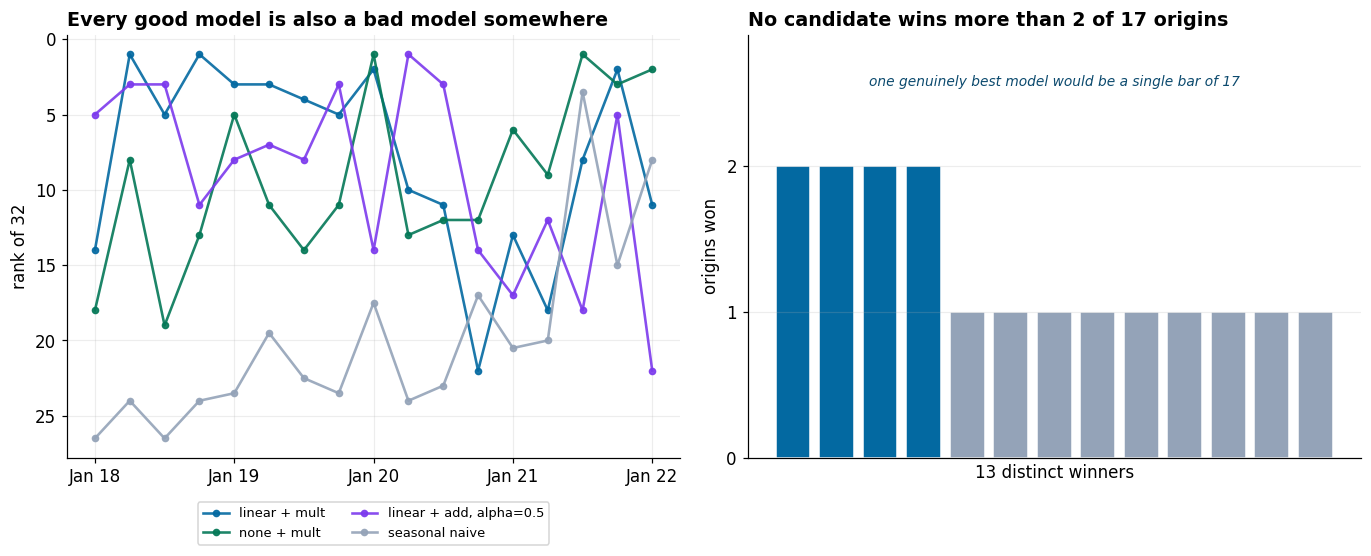

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12.6, 5.2))
short = lambda n: (n.replace("ETS trend=", "").replace(", seasonal=", " + ")
                    .replace("multiplicative", "mult").replace("additive", "add"))
show = list(roll.index[:3]) + ["seasonal naive"]
for nm, c in zip(show, [SK, GD, "#7c3aed", MUT]):
    ax[0].plot(range(len(ORIG)), rk.loc[nm].values, marker="o", ms=4, lw=1.7, color=c,
               label=short(nm), alpha=0.9)
ax[0].invert_yaxis(); ax[0].set_ylabel("rank of 32")
ax[0].set_xticks(range(0, len(ORIG), 4)); ax[0].set_xticklabels([f"{full[ORIG[i]]:%b %y}" for i in range(0, len(ORIG), 4)])
ax[0].set_title("Every good model is also a bad model somewhere")
ax[0].legend(fontsize=8.5, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.09))

vc = w.value_counts()
ax[1].bar(range(len(vc)), vc.values, color=[SK if v > 1 else MUT for v in vc.values], edgecolor="white")
ax[1].set_xticks([]); ax[1].set_ylabel("origins won"); ax[1].set_xlabel(f"{len(vc)} distinct winners")
ax[1].set_yticks([0, 1, 2]); ax[1].set_ylim(0, 2.9)
ax[1].text(len(vc)/2-0.5, 2.55, f"one genuinely best model would be a single bar of {len(ORIG)}",
           ha="center", fontsize=9, color=DK, style="italic")
ax[1].set_title(f"No candidate wins more than {vc.iloc[0]} of {len(ORIG)} origins")
plt.tight_layout(); plt.show()

**Left.** The rank of six candidates at each origin, best at the top. The lines cross constantly. Nothing here is a stable ordering that a single test could have discovered.

**Right.** How many origins each winning candidate won. Thirteen bars, none taller than two. If one model were genuinely best you would see a tall bar; what a one-origin bake-off does is pick a bar at random and call it the champion.

## Step 8 &middot; What the searching costs

In [14]:
sealed = pd.Series({n: float(np.mean([sc(n, o) for o in SEAL])) for n in ALL})   # scored, not read, until Step 9

rng = np.random.default_rng(11); rows = []
for K in [1, 2, 3, 5, 8, 12, 18, 24, len(ALL)]:
    rep, tru = [], []
    for _ in range(4000):
        sub = rng.choice(ALL, size=K, replace=False)
        b = min(sub, key=lambda n: single[n])
        rep.append(single[b]); tru.append(sealed[b])
    rows.append((K, np.mean(rep), np.mean(tru), np.mean(tru)-np.mean(rep)))
OPT = pd.DataFrame(rows, columns=["candidates tried", "reported MAPE %", "true MAPE %", "gap"])
print(OPT.round(2).to_string(index=False))

 candidates tried  reported MAPE %  true MAPE %   gap
                1             7.80         7.56 -0.24
                2             5.14         5.56  0.42
                3             4.57         5.29  0.72
                5             4.13         5.25  1.11
                8             3.88         5.27  1.39
               12             3.67         5.31  1.64
               18             3.50         5.40  1.90
               24             3.40         5.50  2.10
               32             3.34         5.58  2.25


Read the two middle columns against each other, because they move in opposite directions.

**Reported error more than halves as the search widens**, from 7.80 percent for a model picked without looking to 3.34 percent for the best of all thirty-two. **True error drops once, to 5.56 percent at two candidates**, and then sits between 5.25 and 5.58 percent however wide the search. Searching harder made the report better and the forecast no better.

The gap is what the bake-off would overstate its own accuracy by, and it is a function of how many things were tried. At thirty-two candidates it is **2.25 percentage points on a claim of 3.34**.

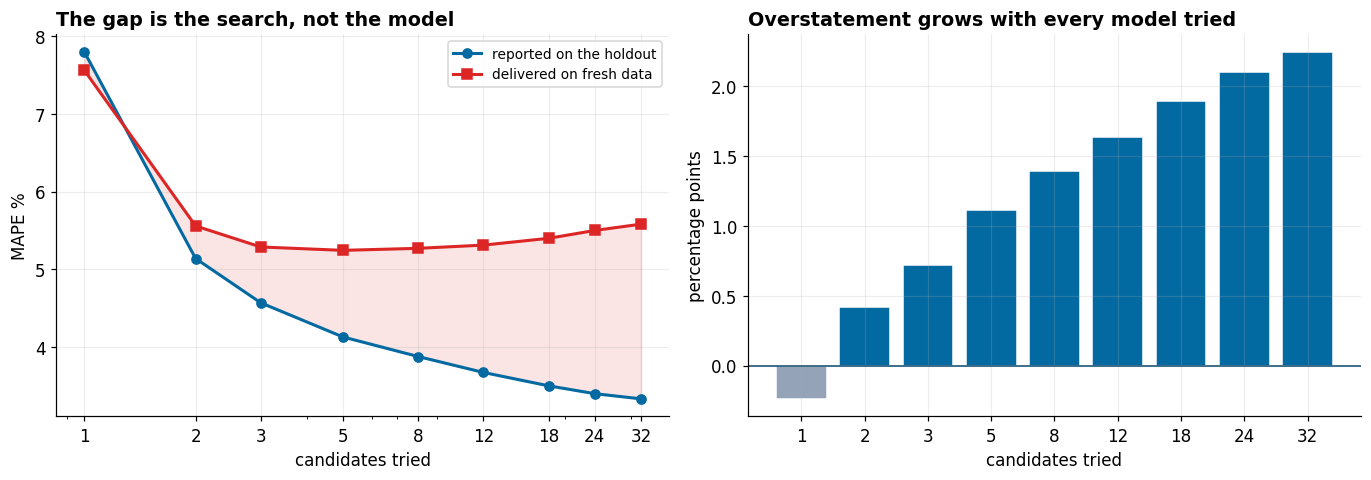

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12.6, 4.5))
ax[0].plot(OPT["candidates tried"], OPT["reported MAPE %"], marker="o", color=SK, lw=2, label="reported on the holdout")
ax[0].plot(OPT["candidates tried"], OPT["true MAPE %"], marker="s", color=RD, lw=2, label="delivered on fresh data")
ax[0].fill_between(OPT["candidates tried"], OPT["reported MAPE %"], OPT["true MAPE %"],
                   color=RD, alpha=0.12)
ax[0].set_xscale("log"); ax[0].set_xticks([1, 2, 3, 5, 8, 12, 18, 24, 32])
ax[0].set_xticklabels([1, 2, 3, 5, 8, 12, 18, 24, 32])
ax[0].set_xlabel("candidates tried"); ax[0].set_ylabel("MAPE %")
ax[0].legend(fontsize=9); ax[0].set_title("The gap is the search, not the model")

ax[1].bar(range(len(OPT)), OPT["gap"], color=[MUT if v < 0 else SK for v in OPT.gap], edgecolor="white")
ax[1].axhline(0, color=DK, lw=1)
ax[1].set_xticks(range(len(OPT))); ax[1].set_xticklabels(OPT["candidates tried"])
ax[1].set_xlabel("candidates tried"); ax[1].set_ylabel("percentage points")
ax[1].set_title("Overstatement grows with every model tried")
plt.tight_layout(); plt.show()

**Left.** The two lines start together and separate. At one candidate there is nothing to select on and the holdout is an honest measurement. Every candidate added after that gives the procedure one more chance to mistake a lucky year for a good model, and the shaded wedge is the accumulated luck.

**Right.** The same wedge as a bar per search size. It turns positive at two candidates and grows without ever flattening. **Nothing about this is specific to forecasting.** Any procedure that reports the best score out of many attempts and does not pay for the search reports a number that is too good.

## Step 9 &middot; Opening the sealed period

In [16]:
print(f"three years never used to choose anything: {full[SEAL[0]]:%b %Y} to {full[-1]:%b %Y}\n")
res = pd.DataFrame({
    "chosen by":   ["one holdout (the bake-off)", "rolling origin", "hindsight", "no model at all"],
    "model":       [W1[:38], WR[:38], sealed.idxmin()[:38], "seasonal naive"],
    "claimed %":   [single.iloc[0], roll.iloc[0], np.nan, np.nan],
    "delivered %": [sealed[W1], sealed[WR], sealed.min(), sealed["seasonal naive"]]})
print(res.round(2).to_string(index=False))
print(f"\nthe bake-off delivered {sealed[W1]/single.iloc[0]-1:+.0%} against its own claim")
print(f"rolling origin delivered {sealed[WR]/roll.iloc[0]-1:+.0%} against its claim\n")
for o in SEAL:
    print(f"  {full[o]:%Y}  growth {y[o:o+H].sum()/y[o-H:o].sum()-1:+5.1%}   "
          f"bake-off {sc(W1,o):5.2f}%   rolling {sc(WR,o):5.2f}%   seasonal naive {sc('seasonal naive',o):5.2f}%")

three years never used to choose anything: Jan 2023 to Dec 2025

                 chosen by                                  model  claimed %  delivered %
one holdout (the bake-off) ETS trend=none, seasonal=additive, alp       3.34         5.58
            rolling origin ETS trend=linear, seasonal=multiplicat       5.47         4.62
                 hindsight    ETS trend=damped, seasonal=additive        NaN         4.52
           no model at all                         seasonal naive        NaN         6.76

the bake-off delivered +67% against its own claim
rolling origin delivered -16% against its claim

  2023  growth +0.7%   bake-off  5.33%   rolling  5.10%   seasonal naive  6.56%
  2024  growth +0.6%   bake-off  4.49%   rolling  4.24%   seasonal naive  6.54%
  2025  growth +7.9%   bake-off  6.93%   rolling  4.53%   seasonal naive  7.19%


**The bake-off promised 3.34 percent and delivered 5.58.** Its error was two-thirds higher than the number the production plan, the hiring plan and the raw-material contracts were built on.

**Rolling-origin selection promised 5.47 percent and delivered 4.62.** It claimed a worse number and produced a better forecast, which is the whole trade this chapter is arguing for. It also came within a tenth of a point of the model that hindsight says was the best of the thirty-two, which delivered 4.52, and how close it came is partly luck. What is not luck is the direction: a claim built from many origins was conservative, and a claim built from one was not.

**The year-by-year rows show the mechanism rather than just the outcome.** 2023 and 2024 were flat and the two models are about a quarter of a point apart. 2025 grew 7.9 percent, and the model that had been chosen for its performance on a flat year posted 6.93 percent against the other's 4.53, half again as much error. It was never a worse model in general. It was a model selected on evidence that contained no growth, and it failed on the first year that had some.

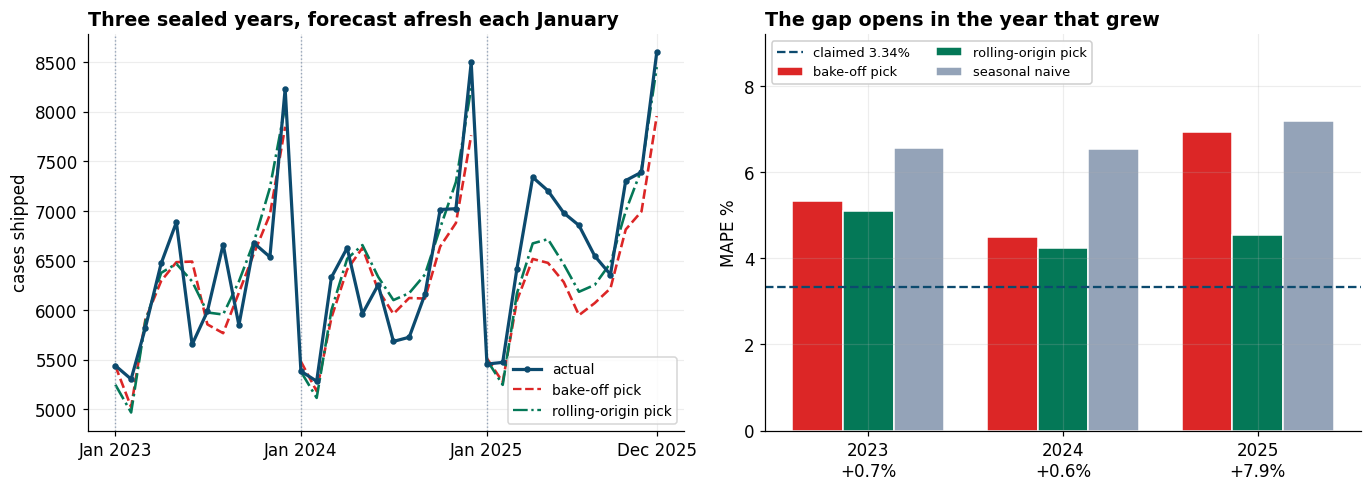

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12.6, 4.6))
ax[0].plot(full[SEAL[0]:], y[SEAL[0]:], color=DK, lw=2.1, marker="o", ms=3.2, label="actual", zorder=5)
for o in SEAL:
    ax[0].plot(full[o:o+H], fc(W1, o), color=RD, lw=1.7, ls="--")
    ax[0].plot(full[o:o+H], fc(WR, o), color=GD, lw=1.7, ls="-.")
    ax[0].axvline(full[o], color=MUT, lw=0.9, ls=":")
ax[0].plot([], [], color=RD, ls="--", label="bake-off pick")
ax[0].plot([], [], color=GD, ls="-.", label="rolling-origin pick")
ax[0].legend(fontsize=9); ax[0].set_ylabel("cases shipped")
ax[0].set_xticks([full[o] for o in SEAL] + [full[-1]])
ax[0].set_xticklabels([f"{full[o]:%b %Y}" for o in SEAL] + [f"{full[-1]:%b %Y}"])
ax[0].set_title("Three sealed years, forecast afresh each January")

xs = np.arange(3); wdt = 0.26
ax[1].bar(xs-wdt, [sc(W1, o) for o in SEAL], wdt, color=RD, label="bake-off pick", edgecolor="white")
ax[1].bar(xs,      [sc(WR, o) for o in SEAL], wdt, color=GD, label="rolling-origin pick", edgecolor="white")
ax[1].bar(xs+wdt, [sc("seasonal naive", o) for o in SEAL], wdt, color=MUT, label="seasonal naive", edgecolor="white")
ax[1].axhline(single.iloc[0], color=DK, lw=1.5, ls="--", label=f"claimed {single.iloc[0]:.2f}%")
ax[1].set_xticks(xs); ax[1].set_xticklabels([f"{full[o]:%Y}\n{y[o:o+H].sum()/y[o-H:o].sum()-1:+.1%}" for o in SEAL])
ax[1].set_ylim(0, 9.2)
ax[1].set_ylabel("MAPE %"); ax[1].legend(fontsize=8.5, ncol=2, loc="upper left", framealpha=0.95)
ax[1].set_title("The gap opens in the year that grew")
plt.tight_layout(); plt.show()

**Left.** Both models track the shape of the sealed years, which is why this is a story about degree rather than disaster. The dashed line drifts below the actual in the third year, where growth resumed.

**Right.** Error by year with the claimed 3.34 percent drawn across. **Neither model reaches that line in any of the three years.** The claim was not merely optimistic on average, it was never met.

## Step 10 &middot; The interval nobody checked

In [18]:
COV = list(range(60, DEV-H+1))                       # every month, development window only
hit, wide = np.zeros(H), []
for o in COV:
    tr = y[:o]; f, m = _ets(tr, SPECS[WR], H)
    sd = float(np.std(tr - np.asarray(m.fittedvalues), ddof=1))
    a  = y[o:o+H]
    hit += ((a >= f-1.96*sd) & (a <= f+1.96*sd)).astype(float); wide.append(2*1.96*sd)
cov = hit/len(COV)
print(f"forecast plus or minus 1.96 x the residual standard deviation, the usual shortcut")
print(f"nominal 95%, measured over {len(COV)} origins x {H} months = {len(COV)*H} points\n")
print(f"  overall coverage   {cov.mean():.1%}")
for lo, hi, lab in [(0,3,"h1 to h3"), (3,6,"h4 to h6"), (6,9,"h7 to h9"), (9,12,"h10 to h12")]:
    print(f"  {lab:10s}         {cov[lo:hi].mean():.0%}")
print(f"\n  one month ahead    {cov[0]:.0%}")
print(f"  twelve months      {cov[11]:.0%}")

forecast plus or minus 1.96 x the residual standard deviation, the usual shortcut
nominal 95%, measured over 49 origins x 12 months = 588 points

  overall coverage   67.9%
  h1 to h3           77%
  h4 to h6           70%
  h7 to h9           63%
  h10 to h12         62%

  one month ahead    82%
  twelve months      57%


**An interval that is supposed to miss one month in twenty misses one month in three.** That is not a small calibration error. A planner told there is a 95 percent chance the month lands inside a band, and then finding the truth outside it a third of the time, has been given a number that means nothing.

Two separate faults are stacked here, and it is worth separating them.

**It is too narrow everywhere.** Even one month ahead, coverage is 82 percent rather than 95. Residuals are what is left after the model has already adapted to those months; they measure how well it fits, not how well it forecasts, and using them as a forecast error understates by construction.

**It is the same width at twelve months as at one.** Coverage falls from 82 percent to 57 percent as the horizon lengthens, because uncertainty about next December compounds every month of drift between here and there while the interval does not widen by a single case.

## Step 11 &middot; An interval measured instead of assumed

In [19]:
err = {h: [] for h in range(H)}
for o in COV:
    f = fc(WR, o); a = y[o:o+H]
    for h in range(H): err[h].append((a[h]-f[h])/f[h])
Q = {h: np.quantile(err[h], [0.025, 0.975]) for h in range(H)}
print("width of the measured band, as a percentage of the forecast:")
print("  " + "   ".join(f"h{h+1} {Q[h][1]-Q[h][0]:.0%}" for h in [0, 3, 7, 11]))

flat_hit = emp_hit = 0
for o in SEAL:
    tr = y[:o]; f, m = _ets(tr, SPECS[WR], H)
    sd = float(np.std(tr - np.asarray(m.fittedvalues), ddof=1)); a = y[o:o+H]
    flat_hit += int(((a >= f-1.96*sd) & (a <= f+1.96*sd)).sum())
    emp_hit  += sum(f[h]*(1+Q[h][0]) <= a[h] <= f[h]*(1+Q[h][1]) for h in range(H))
n = len(SEAL)*H
print(f"\non the sealed period, nominal 95%:")
print(f"  residual shortcut    {flat_hit/n:.0%}   ({flat_hit} of {n} months inside)")
print(f"  measured by horizon  {emp_hit/n:.0%}   ({emp_hit} of {n} months inside)")
f0 = fc(WR, SEAL[0])
print(f"\nwidth at h1   shortcut {np.median(wide):6,.0f} cases   measured {f0[0]*(Q[0][1]-Q[0][0]):6,.0f}")
print(f"width at h12  shortcut {np.median(wide):6,.0f} cases   measured {f0[11]*(Q[11][1]-Q[11][0]):6,.0f}"
      f"   ({f0[11]*(Q[11][1]-Q[11][0])/np.median(wide):.1f}x wider)")

width of the measured band, as a percentage of the forecast:
  h1 21%   h4 22%   h8 25%   h12 29%

on the sealed period, nominal 95%:
  residual shortcut    83%   (30 of 36 months inside)
  measured by horizon  94%   (34 of 36 months inside)

width at h1   shortcut    897 cases   measured  1,096
width at h12  shortcut    897 cases   measured  2,346   (2.6x wider)


**The backtest has already generated the thing the interval needed.** Forty-nine origins, each producing a one-month-ahead error, a two-month-ahead error, and so on out to twelve. Taking the 2.5th and 97.5th percentiles of those errors *at each horizon separately* gives a band built from what the model has actually done rather than from an assumption about what it should do.

It covers 94 percent of the sealed months against a nominal 95, where the shortcut managed 83.

**It is wider than the shortcut at every horizon, but not by a constant amount.** At one month it is 1,096 cases against 897, a modest correction. At twelve it is 2,346 against the same 897, **2.6 times wider.** The shortcut was not simply too small by some factor that could be patched with a fudge multiplier. It was the wrong shape: mildly over-confident about next month and badly over-confident about next December.

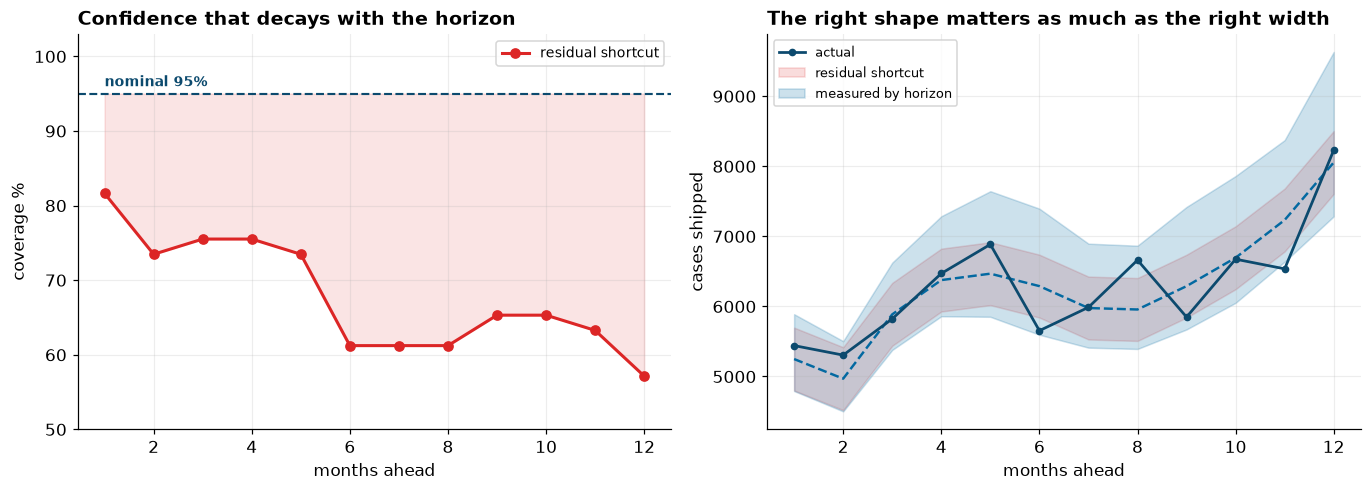

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12.6, 4.6))
ax[0].plot(range(1, H+1), cov*100, marker="o", color=RD, lw=2, label="residual shortcut")
ax[0].axhline(95, color=DK, lw=1.4, ls="--"); ax[0].text(1, 96, "nominal 95%", fontsize=9, color=DK, fontweight="bold")
ax[0].fill_between(range(1, H+1), cov*100, 95, color=RD, alpha=0.12)
ax[0].set_xlabel("months ahead"); ax[0].set_ylabel("coverage %"); ax[0].set_ylim(50, 103)
ax[0].legend(fontsize=9); ax[0].set_title("Confidence that decays with the horizon")

o = SEAL[0]; f = fc(WR, o); sd = np.median(wide)/(2*1.96)
ax[1].plot(range(1, H+1), y[o:o+H], color=DK, lw=1.8, marker="o", ms=4, label="actual", zorder=5)
ax[1].fill_between(range(1, H+1), f-1.96*sd, f+1.96*sd, color=RD, alpha=0.16, label="residual shortcut")
ax[1].fill_between(range(1, H+1), [f[h]*(1+Q[h][0]) for h in range(H)],
                   [f[h]*(1+Q[h][1]) for h in range(H)], color=SK, alpha=0.20, label="measured by horizon")
ax[1].plot(range(1, H+1), f, color=SK, lw=1.6, ls="--")
ax[1].set_xlabel("months ahead"); ax[1].set_ylabel("cases shipped"); ax[1].legend(fontsize=8.5)
ax[1].set_title("The right shape matters as much as the right width")
plt.tight_layout(); plt.show()

**Left.** Coverage against the horizon. A well-calibrated interval would sit on the dashed line at every horizon. The shortcut starts thirteen points below it and falls away, and the shaded area is the gap between what the planner was promised and what they got.

**Right.** The two bands drawn over the first sealed year. The measured band opens as the year runs on, which is what genuine uncertainty about a wandering level looks like. The shortcut is a corridor of constant width, already slightly too tight in January and indefensible by December.

## Step 12 &middot; What we would tell the planning team

In [21]:
print(f"the claim on the table       3.34% MAPE, from one holdout, best of {len(ALL)}")
print(f"what that model delivered    {sealed[W1]:.2f}% on three sealed years ({sealed[W1]/single.iloc[0]-1:+.0%})")
print(f"what we recommend instead    {WR}")
print(f"expected accuracy            {roll.iloc[0]:.1f}% MAPE, the rolling-origin average")
print(f"what it delivered sealed     {sealed[WR]:.2f}%")
print(f"planning band for next Dec   {f0[11]*(1+Q[11][0]):,.0f} to {f0[11]*(1+Q[11][1]):,.0f} cases")
print(f"floor to beat                seasonal naive at {sealed['seasonal naive']:.2f}%")

the claim on the table       3.34% MAPE, from one holdout, best of 32
what that model delivered    5.58% on three sealed years (+67%)
what we recommend instead    ETS trend=linear, seasonal=multiplicative
expected accuracy            5.5% MAPE, the rolling-origin average
what it delivered sealed     4.62%
planning band for next Dec   7,285 to 9,631 cases
floor to beat                seasonal naive at 6.76%


**Plan on about five and a half percent, not three and a half.** The honest expectation for this series and this method is the rolling-origin figure, and it should be quoted as a range rather than a point. The 3.4 percent was never a property of the model; it was a property of having tried thirty-two of them against one flat year.

**Quote December as a range, and make it a wide one.** The shortcut offered a band 900 cases wide for a month twelve months out. The measured band is 2,346, and a raw-material contract written against the point estimate is a contract written against a number nobody should have believed.

**Re-run the selection every year, and keep the seasonal naive rule in the comparison.** It delivered 6.76 percent on the sealed years without being fitted to anything. The chosen model beats it by about two points, which is a real gain and a modest one, and the day it stops beating it is the day the model has quietly broken.

**What this does not settle.** Three sealed years is three draws, not a large sample, and how close the rolling-origin pick came to the hindsight best is luck as much as method. Two of the 156 months were interpolated across the 2017 gap and every backtest trains through them. And the whole exercise scores one series with one metric: MAPE penalizes over-forecasting and under-forecasting differently, and a business that would rather hold stock than miss an order should be selecting on a loss function that says so.